# Quantization Efficiency Analysis — FP32 vs Runtime Dynamic INT8

This notebook is a **standalone efficiency benchmark** built to match the project's existing `quantization.ipynb`.

It does **not train** a model and does **not require a saved INT8 checkpoint**.

Actual project pipeline reproduced here:

```text
models/fp32/seed<SEED>/final
          │
          ├─────────────── FP32 benchmark
          │
          └─ deepcopy → TorchAO quantize_
                         Int8DynamicActivationInt8WeightConfig
                                  │
                                  └─ INT8 benchmark
```

## Primary metrics

1. Serialized model-state size
2. Registered parameter/buffer tensor memory
3. Peak inference memory
4. Inference latency
5. Throughput
6. Runtime process/device memory
7. Full HANS inference time

The notebook also records **runtime quantization setup time** as a supplementary measurement.

---

## 🔴 CELLS YOU MAY NEED TO CHANGE

Only cells explicitly headed **🔴 USER CONFIGURATION** should normally require editing.

For the current project structure, the defaults already match:

- FP32 models: `../models/fp32/seed<SEED>/final`
- HANS: official raw HANS TSV used by `quantization.ipynb`
- Results: `../results/efficiency`
- `MAX_LENGTH = 128`
- `BATCH_SIZE = 32`

Start with seed 42. After it works, change only `SEED` to 123 and 456.

## 1. Imports

In [1]:
from pathlib import Path
import copy
import gc
import io
import json
import os
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchao

from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
)
from torchao.quantization import (
    quantize_,
    Int8DynamicActivationInt8WeightConfig,
)

try:
    import psutil
except ImportError:
    psutil = None

print("PyTorch:", torch.__version__)
print("TorchAO:", torchao.__version__)
print("Platform:", platform.platform())
print("CUDA available:", torch.cuda.is_available())
print(
    "MPS available:",
    hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
)

W0926 00:17:38.558000 120131 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


PyTorch: 2.14.0+cu130
TorchAO: 0.18.0
Platform: Linux-7.1.5-76070105-generic-x86_64-with-glibc2.39
CUDA available: True
MPS available: False


## 🔴 2. USER CONFIGURATION — CHECK THIS CELL

**This is the main cell you change.**

For your existing directory structure, normally change only:

```python
SEED = 42
```

to `123` or `456` for the other runs.

If this notebook sits in the same notebook directory as your existing quantization notebook, the paths below match your project.

In [2]:
# ============================================================
# 🔴 USER CONFIGURATION
# ============================================================

SEED = 42

MAX_LENGTH = 128
BATCH_SIZE = 32

# Number of untimed warm-up batches before measuring latency.
WARMUP_BATCHES = 20

# None = benchmark all 30,000 HANS examples.
# For a quick debugging run, temporarily use e.g. 1000.
MAX_EXAMPLES = None

# Existing project model layout:
MODEL_PATH = Path(f"../models/fp32/seed{SEED}/final")

# Benchmark outputs:
RESULTS_DIR = Path("../results/efficiency")

# Same official HANS source used in your quantization.ipynb.
HANS_URL = (
    "https://raw.githubusercontent.com/tommccoy1/hans/"
    "master/heuristics_evaluation_set.txt"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Seed:", SEED)
print("Model path:", MODEL_PATH)
print("Results directory:", RESULTS_DIR)
print("Batch size:", BATCH_SIZE)
print("Max length:", MAX_LENGTH)

Seed: 42
Model path: ../models/fp32/seed42/final
Results directory: ../results/efficiency
Batch size: 32
Max length: 128


## 3. Validate paths

If this cell fails with `Model directory not found`, the notebook is being run from a different working directory than your original notebooks.

In that case, change **only `MODEL_PATH` in the USER CONFIGURATION cell above**.

In [3]:
print("Current working directory:", Path.cwd())
print("Resolved model path:", MODEL_PATH.resolve())

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model directory not found: {MODEL_PATH.resolve()}\n"
        "Update MODEL_PATH in the USER CONFIGURATION cell."
    )

print("✓ FP32 model directory found")

Current working directory: /home/mohnishr/workspace/DLBA/Quantization-Spurious-Heuristics-in-Transformers/notebooks
Resolved model path: /home/mohnishr/workspace/DLBA/Quantization-Spurious-Heuristics-in-Transformers/models/fp32/seed42/final
✓ FP32 model directory found


## 4. Benchmark device

The benchmark uses one device/backend for **both FP32 and INT8**.

TorchAO dynamic INT8 kernel support is backend-dependent. This cell chooses CUDA when available, then MPS, otherwise CPU.

If the INT8 model cannot execute on the selected accelerator in your installed TorchAO/PyTorch environment, set `DEVICE = torch.device("cpu")` here and benchmark **both models on CPU**. Do not compare FP32 on one backend with INT8 on another as a quantization speedup.

In [4]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Benchmark device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Benchmark device: cuda
GPU: NVIDIA GeForce RTX 5080 Laptop GPU


## 5. Load FP32 model and tokenizer

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model_fp32 = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH
)
model_fp32.eval()

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)

print("✓ FP32 model loaded")
print("Labels:", model_fp32.config.id2label)

W0926 00:19:21.173000 120131 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ FP32 model loaded
Labels: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


## 6. Create runtime INT8 model

This is intentionally the same procedure used by your existing `quantization.ipynb`.

The quantized model is created in memory and is **not saved as a checkpoint**.

In [6]:
quantization_start = time.perf_counter()

model_int8 = copy.deepcopy(model_fp32)

quantize_(
    model_int8,
    Int8DynamicActivationInt8WeightConfig()
)

model_int8.eval()

quantization_seconds = time.perf_counter() - quantization_start

print("✓ Dynamic INT8 quantization completed")
print(f"Runtime quantization setup time: {quantization_seconds:.3f} seconds")

✓ Dynamic INT8 quantization completed
Runtime quantization setup time: 0.386 seconds


## 7. Load HANS — same method as your quantization notebook

This deliberately **does not use**:

```python
load_dataset("hans")
```

because newer `datasets` versions reject the legacy `hans.py` dataset script.

Instead, it uses the same official raw HANS TSV URL already used successfully in your `quantization.ipynb`.

In [7]:
hans_dataset = load_dataset(
    "csv",
    data_files={"validation": HANS_URL},
    delimiter="\t",
)

hans = hans_dataset["validation"]

hans_eval = hans.rename_columns({
    "sentence1": "premise",
    "sentence2": "hypothesis",
})

if MAX_EXAMPLES is not None:
    hans_eval = hans_eval.select(
        range(min(MAX_EXAMPLES, len(hans_eval)))
    )

print("HANS examples:", len(hans_eval))
print("First premise:", hans_eval[0]["premise"])
print("First hypothesis:", hans_eval[0]["hypothesis"])

Generating validation split: 0 examples [00:00, ? examples/s]

HANS examples: 30000
First premise: The president advised the doctor .
First hypothesis: The doctor advised the president .


## 8. Tokenize HANS and build DataLoader

This matches your existing settings:

- tokenizer from the fine-tuned FP32 checkpoint
- truncation
- `MAX_LENGTH = 128`
- dynamic padding
- `BATCH_SIZE = 32`
- no shuffle

Labels and HANS metadata are not needed for an efficiency benchmark.

In [8]:
def tokenize_hans(batch):
    return tokenizer(
        batch["premise"],
        batch["hypothesis"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

hans_tokenized = hans_eval.map(
    tokenize_hans,
    batched=True,
)

# BERT normally has token_type_ids. Build the list defensively.
model_columns = [
    col
    for col in ["input_ids", "token_type_ids", "attention_mask"]
    if col in hans_tokenized.column_names
]

hans_model_inputs = hans_tokenized.select_columns(model_columns)

hans_loader = DataLoader(
    hans_model_inputs,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator,
)

print("Model input columns:", model_columns)
print(f"Examples: {len(hans_model_inputs):,}")
print(f"Batches: {len(hans_loader):,}")

expected_batches = int(np.ceil(len(hans_model_inputs) / BATCH_SIZE))
assert len(hans_loader) == expected_batches

if MAX_EXAMPLES is None:
    assert len(hans_model_inputs) == 30000, (
        f"Expected 30,000 HANS examples, got {len(hans_model_inputs):,}"
    )

print("✓ HANS benchmark workload ready")

Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Model input columns: ['input_ids', 'token_type_ids', 'attention_mask']
Examples: 30,000
Batches: 938
✓ HANS benchmark workload ready


# Metric 1 — Serialized model-state size

Because INT8 exists only at runtime, there is no INT8 model directory to compare against.

For a fair FP32-vs-INT8 measurement, this cell serializes each model's `state_dict()` to an **in-memory buffer** using the same method and measures the number of bytes.

Nothing is written to disk.

In [9]:
def serialized_state_size_mib(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    nbytes = buffer.tell()
    buffer.close()
    return nbytes / (1024 ** 2)

fp32_serialized_mib = serialized_state_size_mib(model_fp32)
int8_serialized_mib = serialized_state_size_mib(model_int8)

storage_df = pd.DataFrame([
    {"model": "FP32", "serialized_state_MiB": fp32_serialized_mib},
    {"model": "INT8", "serialized_state_MiB": int8_serialized_mib},
])

display(storage_df)

storage_reduction = 100 * (
    1 - int8_serialized_mib / fp32_serialized_mib
)
storage_ratio = fp32_serialized_mib / int8_serialized_mib

print(f"Compression ratio: {storage_ratio:.3f}x")
print(f"Serialized-state reduction: {storage_reduction:.2f}%")

,model,serialized_state_MiB
0,FP32,417.725385
1,INT8,173.480046


Compression ratio: 2.408x
Serialized-state reduction: 58.47%


# Metric 2 — Registered tensor memory

This sums registered parameters and buffers according to their actual tensor dtype and element size.

For backend-specific packed/quantized representations, this is a useful model-tensor measurement but may not equal total runtime allocator memory. Metrics 3 and 6 capture operational memory separately.

In [10]:
def tensor_memory_stats(model):
    parameter_bytes = sum(
        p.numel() * p.element_size()
        for p in model.parameters()
    )
    buffer_bytes = sum(
        b.numel() * b.element_size()
        for b in model.buffers()
    )

    return {
        "parameter_MiB": parameter_bytes / (1024 ** 2),
        "buffer_MiB": buffer_bytes / (1024 ** 2),
        "registered_tensor_MiB":
            (parameter_bytes + buffer_bytes) / (1024 ** 2),
    }

tensor_memory_df = pd.DataFrame([
    {"model": "FP32", **tensor_memory_stats(model_fp32)},
    {"model": "INT8", **tensor_memory_stats(model_int8)},
])

display(tensor_memory_df)

,model,parameter_MiB,buffer_MiB,registered_tensor_MiB
0,FP32,417.650402,0.007812,417.658215
1,INT8,417.650402,0.007812,417.658215


# Metrics 3–7 — Runtime benchmark

The same benchmark run provides:

- **3:** peak inference memory
- **4:** latency
- **5:** throughput
- **6:** runtime memory
- **7:** complete HANS inference time

Important distinction:

- Warm-up batches are run first and **not timed**.
- The subsequent timed pass still processes the **entire selected HANS workload**.
- Accelerator synchronization is used around timing.

In [11]:
def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        try:
            torch.mps.synchronize()
        except Exception:
            pass


def process_rss_mib():
    if psutil is None:
        return np.nan

    return (
        psutil.Process(os.getpid()).memory_info().rss
        / (1024 ** 2)
    )


def device_memory_allocated_mib(device):
    if device.type == "cuda":
        return (
            torch.cuda.memory_allocated(device)
            / (1024 ** 2)
        )

    if device.type == "mps":
        try:
            return (
                torch.mps.current_allocated_memory()
                / (1024 ** 2)
            )
        except Exception:
            return np.nan

    return np.nan


def reset_memory_tracking(device):
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)

    elif device.type == "mps":
        try:
            torch.mps.empty_cache()
        except Exception:
            pass


def allocator_peak_mib(device):
    if device.type == "cuda":
        return (
            torch.cuda.max_memory_allocated(device)
            / (1024 ** 2)
        )

    # No directly equivalent peak allocator API is assumed for MPS.
    return np.nan

In [12]:
def benchmark_model(
    model,
    dataloader,
    device,
    model_name,
    warmup_batches=20,
):
    # Move model first, then clear/reset measurement state.
    model = model.to(device)
    model.eval()

    reset_memory_tracking(device)

    # -------------------------
    # Warm-up
    # -------------------------
    with torch.inference_mode():
        for batch_idx, batch in enumerate(dataloader):
            if batch_idx >= warmup_batches:
                break

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            _ = model(**batch)

    synchronize(device)

    # Warm-up allocations should not count toward CUDA peak.
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)

    # -------------------------
    # Timed full inference pass
    # -------------------------
    rss_before = process_rss_mib()
    device_before = device_memory_allocated_mib(device)

    sampled_rss = [rss_before]
    sampled_device_memory = [device_before]

    batch_latencies_s = []
    batch_sizes = []

    total_examples = 0

    synchronize(device)
    full_start = time.perf_counter()

    with torch.inference_mode():
        for batch in dataloader:
            current_batch_size = batch["input_ids"].shape[0]

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            synchronize(device)
            batch_start = time.perf_counter()

            _ = model(**batch)

            synchronize(device)
            batch_elapsed = time.perf_counter() - batch_start

            batch_latencies_s.append(batch_elapsed)
            batch_sizes.append(current_batch_size)
            total_examples += current_batch_size

            sampled_rss.append(process_rss_mib())
            sampled_device_memory.append(
                device_memory_allocated_mib(device)
            )

    synchronize(device)
    end_to_end_seconds = time.perf_counter() - full_start

    rss_after = process_rss_mib()
    device_after = device_memory_allocated_mib(device)

    valid_rss = [
        x for x in sampled_rss
        if np.isfinite(x)
    ]
    valid_device = [
        x for x in sampled_device_memory
        if np.isfinite(x)
    ]

    batch_latencies_ms = (
        np.asarray(batch_latencies_s, dtype=float) * 1000
    )
    batch_sizes_arr = np.asarray(batch_sizes, dtype=float)

    example_latencies_ms = (
        batch_latencies_ms / batch_sizes_arr
    )

    result = {
        "model": model_name,
        "device": str(device),
        "examples": int(total_examples),
        "batches": len(batch_latencies_s),

        # Metric 7
        "end_to_end_seconds": end_to_end_seconds,

        # Metric 5
        "throughput_examples_per_sec":
            total_examples / end_to_end_seconds,

        # Metric 4
        "mean_batch_latency_ms":
            float(batch_latencies_ms.mean()),
        "median_batch_latency_ms":
            float(np.median(batch_latencies_ms)),
        "p95_batch_latency_ms":
            float(np.percentile(batch_latencies_ms, 95)),
        "mean_example_latency_ms":
            float(example_latencies_ms.mean()),
        "median_example_latency_ms":
            float(np.median(example_latencies_ms)),

        # Metrics 3 / 6
        "process_rss_before_MiB": rss_before,
        "process_rss_after_MiB": rss_after,
        "peak_sampled_process_rss_MiB":
            max(valid_rss) if valid_rss else np.nan,

        "device_memory_before_MiB": device_before,
        "device_memory_after_MiB": device_after,
        "peak_sampled_device_memory_MiB":
            max(valid_device) if valid_device else np.nan,

        "allocator_peak_device_memory_MiB":
            allocator_peak_mib(device),
    }

    # Return model to CPU before benchmarking the next model.
    model.to("cpu")
    synchronize(device)
    reset_memory_tracking(device)

    return result, batch_latencies_ms

## 9. Benchmark FP32

This performs warm-up followed by one full timed HANS inference pass.

In [13]:
fp32_runtime, fp32_batch_latencies_ms = benchmark_model(
    model=model_fp32,
    dataloader=hans_loader,
    device=DEVICE,
    model_name="FP32",
    warmup_batches=WARMUP_BATCHES,
)

display(pd.DataFrame([fp32_runtime]))

,model,device,examples,batches,end_to_end_seconds,throughput_examples_per_sec,mean_batch_latency_ms,median_batch_latency_ms,p95_batch_latency_ms,mean_example_latency_ms,median_example_latency_ms,process_rss_before_MiB,process_rss_after_MiB,peak_sampled_process_rss_MiB,device_memory_before_MiB,device_memory_after_MiB,peak_sampled_device_memory_MiB,allocator_peak_device_memory_MiB
0,FP32,cuda,30000,938,13.218706,2269.511143,12.758484,12.596121,14.671848,0.399421,0.393629,1692.667969,1812.71875,1812.710938,450.739258,450.746582,450.756836,475.524414


## 10. Benchmark INT8

The same DataLoader, device, batch size, and timing procedure are used.

In [14]:
int8_runtime, int8_batch_latencies_ms = benchmark_model(
    model=model_int8,
    dataloader=hans_loader,
    device=DEVICE,
    model_name="INT8",
    warmup_batches=WARMUP_BATCHES,
)

display(pd.DataFrame([int8_runtime]))

,model,device,examples,batches,end_to_end_seconds,throughput_examples_per_sec,mean_batch_latency_ms,median_batch_latency_ms,p95_batch_latency_ms,mean_example_latency_ms,median_example_latency_ms,process_rss_before_MiB,process_rss_after_MiB,peak_sampled_process_rss_MiB,device_memory_before_MiB,device_memory_after_MiB,peak_sampled_device_memory_MiB,allocator_peak_device_memory_MiB
0,INT8,cuda,30000,938,89.867451,333.824978,94.355092,94.364643,95.699309,2.952234,2.948895,2252.378906,2254.671875,2254.671875,206.460449,206.467773,206.478027,240.249512


## 11. Runtime comparison

In [15]:
runtime_df = pd.DataFrame([
    fp32_runtime,
    int8_runtime,
])

display(runtime_df)

,model,device,examples,batches,end_to_end_seconds,throughput_examples_per_sec,mean_batch_latency_ms,median_batch_latency_ms,p95_batch_latency_ms,mean_example_latency_ms,median_example_latency_ms,process_rss_before_MiB,process_rss_after_MiB,peak_sampled_process_rss_MiB,device_memory_before_MiB,device_memory_after_MiB,peak_sampled_device_memory_MiB,allocator_peak_device_memory_MiB
0,FP32,cuda,30000,938,13.218706,2269.511143,12.758484,12.596121,14.671848,0.399421,0.393629,1692.667969,1812.718750,1812.710938,450.739258,450.746582,450.756836,475.524414
1,INT8,cuda,30000,938,89.867451,333.824978,94.355092,94.364643,95.699309,2.952234,2.948895,2252.378906,2254.671875,2254.671875,206.460449,206.467773,206.478027,240.249512


## 12. Final seven-metric table

For peak inference memory:

1. CUDA allocator peak is preferred when available.
2. Otherwise sampled device memory is used.
3. Otherwise sampled process RSS is used.

The table explicitly records which memory source was used.

In [16]:
def row_value(df, model_name, column):
    return float(
        df.loc[df["model"] == model_name, column].iloc[0]
    )


def percent_reduction(fp32, int8):
    if not (
        np.isfinite(fp32)
        and np.isfinite(int8)
        and fp32 != 0
    ):
        return np.nan

    return 100 * (1 - int8 / fp32)


# Determine best available peak-memory metric.
memory_candidates = [
    (
        "allocator_peak_device_memory_MiB",
        "device allocator peak",
    ),
    (
        "peak_sampled_device_memory_MiB",
        "sampled device memory",
    ),
    (
        "peak_sampled_process_rss_MiB",
        "sampled process RSS",
    ),
]

peak_column = None
peak_source = None

for candidate, source in memory_candidates:
    fp = row_value(runtime_df, "FP32", candidate)
    q = row_value(runtime_df, "INT8", candidate)

    if np.isfinite(fp) and np.isfinite(q):
        peak_column = candidate
        peak_source = source
        break

if peak_column is None:
    raise RuntimeError(
        "No usable runtime memory measurement was available."
    )


final_rows = []

# 1
fp = row_value(storage_df, "FP32", "serialized_state_MiB")
q = row_value(storage_df, "INT8", "serialized_state_MiB")
final_rows.append({
    "metric": "1. Serialized model-state size",
    "FP32": fp,
    "INT8": q,
    "unit": "MiB",
    "comparison":
        f"{percent_reduction(fp, q):.2f}% reduction",
})

# 2
fp = row_value(
    tensor_memory_df, "FP32", "registered_tensor_MiB"
)
q = row_value(
    tensor_memory_df, "INT8", "registered_tensor_MiB"
)
final_rows.append({
    "metric": "2. Registered tensor memory",
    "FP32": fp,
    "INT8": q,
    "unit": "MiB",
    "comparison":
        f"{percent_reduction(fp, q):.2f}% reduction",
})

# 3
fp = row_value(runtime_df, "FP32", peak_column)
q = row_value(runtime_df, "INT8", peak_column)
final_rows.append({
    "metric": f"3. Peak inference memory ({peak_source})",
    "FP32": fp,
    "INT8": q,
    "unit": "MiB",
    "comparison":
        f"{percent_reduction(fp, q):.2f}% reduction",
})

# 4
fp = row_value(
    runtime_df, "FP32", "median_batch_latency_ms"
)
q = row_value(
    runtime_df, "INT8", "median_batch_latency_ms"
)
final_rows.append({
    "metric": "4. Median batch latency",
    "FP32": fp,
    "INT8": q,
    "unit": "ms/batch",
    "comparison": f"{fp / q:.3f}x speedup",
})

# 5
fp = row_value(
    runtime_df, "FP32", "throughput_examples_per_sec"
)
q = row_value(
    runtime_df, "INT8", "throughput_examples_per_sec"
)
final_rows.append({
    "metric": "5. Throughput",
    "FP32": fp,
    "INT8": q,
    "unit": "examples/s",
    "comparison":
        f"{100 * (q / fp - 1):+.2f}% change",
})

# 6 — process memory specifically
fp = row_value(
    runtime_df, "FP32", "peak_sampled_process_rss_MiB"
)
q = row_value(
    runtime_df, "INT8", "peak_sampled_process_rss_MiB"
)
final_rows.append({
    "metric": "6. Peak process runtime memory",
    "FP32": fp,
    "INT8": q,
    "unit": "MiB",
    "comparison":
        (
            f"{percent_reduction(fp, q):.2f}% reduction"
            if np.isfinite(percent_reduction(fp, q))
            else "N/A"
        ),
})

# 7
fp = row_value(
    runtime_df, "FP32", "end_to_end_seconds"
)
q = row_value(
    runtime_df, "INT8", "end_to_end_seconds"
)
final_rows.append({
    "metric": "7. Full HANS inference time",
    "FP32": fp,
    "INT8": q,
    "unit": "seconds",
    "comparison": f"{fp / q:.3f}x speedup",
})

final_table = pd.DataFrame(final_rows)

display(final_table)

print(
    f"Supplementary runtime quantization setup time: "
    f"{quantization_seconds:.3f} seconds"
)

,metric,FP32,INT8,unit,comparison
0,1. Serialized model-state size,417.725385,173.480046,MiB,58.47% reduction
1,2. Registered tensor memory,417.658215,417.658215,MiB,0.00% reduction
2,3. Peak inference memory (device allocator peak),475.524414,240.249512,MiB,49.48% reduction
3,4. Median batch latency,12.596121,94.364643,ms/batch,0.133x speedup
4,5. Throughput,2269.511143,333.824978,examples/s,-85.29% change
5,6. Peak process runtime memory,1812.710938,2254.671875,MiB,-24.38% reduction
6,7. Full HANS inference time,13.218706,89.867451,seconds,0.147x speedup


Supplementary runtime quantization setup time: 0.386 seconds


## 13. Latency distribution

This is a diagnostic plot, not an additional primary metric.

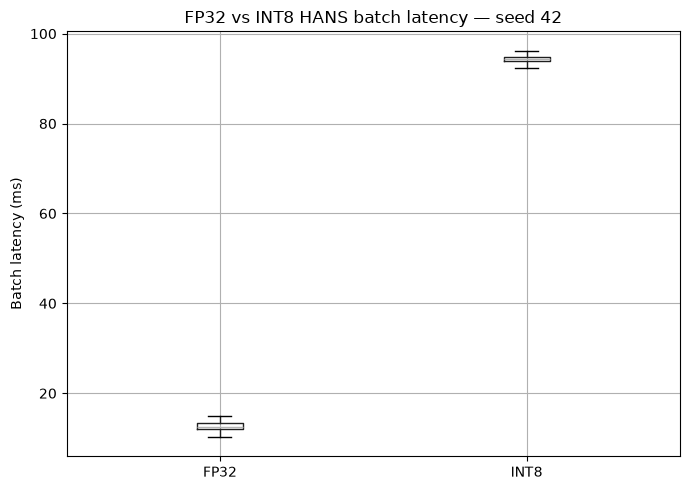

In [17]:
latency_plot_df = pd.DataFrame({
    "FP32": pd.Series(fp32_batch_latencies_ms),
    "INT8": pd.Series(int8_batch_latencies_ms),
})

ax = latency_plot_df.boxplot(
    figsize=(7, 5),
    showfliers=False,
)

ax.set_ylabel("Batch latency (ms)")
ax.set_title(f"FP32 vs INT8 HANS batch latency — seed {SEED}")

plt.tight_layout()
plt.show()

## 14. Save results

Outputs are stored under:

```text
results/
└── efficiency/
    ├── seed42_efficiency_summary.csv
    ├── seed42_runtime.csv
    ├── seed42_storage.csv
    ├── seed42_tensor_memory.csv
    └── seed42_environment.json
```

and similarly for seeds 123 and 456.

In [18]:
environment = {
    "seed": SEED,
    "model_path": str(MODEL_PATH),
    "device": str(DEVICE),
    "platform": platform.platform(),
    "torch_version": torch.__version__,
    "torchao_version": torchao.__version__,
    "cuda_version": torch.version.cuda,
    "batch_size": BATCH_SIZE,
    "max_length": MAX_LENGTH,
    "warmup_batches": WARMUP_BATCHES,
    "num_hans_examples": len(hans_model_inputs),
    "runtime_quantization_setup_seconds":
        quantization_seconds,
}

if DEVICE.type == "cuda":
    environment["gpu_name"] = torch.cuda.get_device_name(0)

storage_df.to_csv(
    RESULTS_DIR / f"seed{SEED}_storage.csv",
    index=False,
)

tensor_memory_df.to_csv(
    RESULTS_DIR / f"seed{SEED}_tensor_memory.csv",
    index=False,
)

runtime_df.to_csv(
    RESULTS_DIR / f"seed{SEED}_runtime.csv",
    index=False,
)

final_table.to_csv(
    RESULTS_DIR / f"seed{SEED}_efficiency_summary.csv",
    index=False,
)

with open(
    RESULTS_DIR / f"seed{SEED}_environment.json",
    "w",
) as f:
    json.dump(environment, f, indent=2)

print("✓ Saved all efficiency results to:")
print(RESULTS_DIR.resolve())

✓ Saved all efficiency results to:
/home/mohnishr/workspace/DLBA/Quantization-Spurious-Heuristics-in-Transformers/results/efficiency


# What you change for the other seeds

After seed 42 completes successfully, return to the **🔴 USER CONFIGURATION** cell and change only:

```python
SEED = 123
```

Run all cells again.

Then:

```python
SEED = 456
```

and run all cells again.

Because `MODEL_PATH` is constructed from `SEED`, it automatically becomes:

```text
../models/fp32/seed123/final
../models/fp32/seed456/final
```

The output filenames also change automatically.

## Normally, do NOT change

- `MAX_LENGTH = 128`
- `BATCH_SIZE = 32`
- HANS URL
- quantization configuration
- tokenizer
- warm-up methodology
- DataLoader settings

Changing those between FP32 and INT8 would weaken the comparison.